## Import libraries

In [1]:
import numpy as np
import pandas as pd
from obspy.geodetics.base import gps2dist_azimuth
import pygmt as pmt

import warnings
warnings.filterwarnings("ignore")

## Load station list

In [2]:
station_table=pd.read_csv("/home/msseo/works/72.2025_Imsil_swarm/station_table/KS_station.csv", sep=",")
station_table.head(5)

,Network,Code,Latitude,Longitude,Elevation
0,KS,BBK,35.57979,129.43559,0.0
1,KS,BGD,34.15690,126.55750,0.0
2,KS,CHYA,36.93780,128.91670,321.0
3,KS,CWS1,38.28810,127.58700,0.0
4,KS,HAK,35.92955,129.50037,0.0


## Location of epicenter

In [3]:
evla, evlo=35.55, 127.30

## Select nearby stations ($\Delta\leq100\mathrm{km}$)

In [4]:
selected_list=[]
for i in range(len(station_table)):
    code=station_table["Code"][i]
    stla, stlo=station_table["Latitude"][i], station_table["Longitude"][i]
    epidist=gps2dist_azimuth(evla, evlo, stla, stlo)[0]/1000 # in kilometers
    
    if epidist <= 100:
        selected_list.append(code)

In [5]:
selected_table=station_table[station_table["Code"].isin(selected_list)].reset_index(drop=True)
selected_table.head(10)

,Network,Code,Latitude,Longitude,Elevation
0,KS,KMC,35.98692,127.94262,0.0
1,KS,BAU,35.10270,127.59680,562.0
2,KS,BLGA,36.13920,127.30320,105.0
3,KS,BLLA,34.86460,127.46380,45.0
4,KS,BUYB,36.27260,126.92060,59.0
5,KS,CGPA,34.87680,126.97100,144.0
6,KS,CHI,35.20320,128.11940,21.0
7,KS,CHO(p),35.81780,127.15420,53.0
8,KS,CHOA,35.84070,127.11710,102.0
9,KS,CJDB,36.17400,126.52840,55.0


In [6]:
selected_table.to_csv("/home/msseo/works/72.2025_Imsil_swarm/station_table/kma_stations_100km.csv", index=False)

## Draw the map of stations together with epiceters

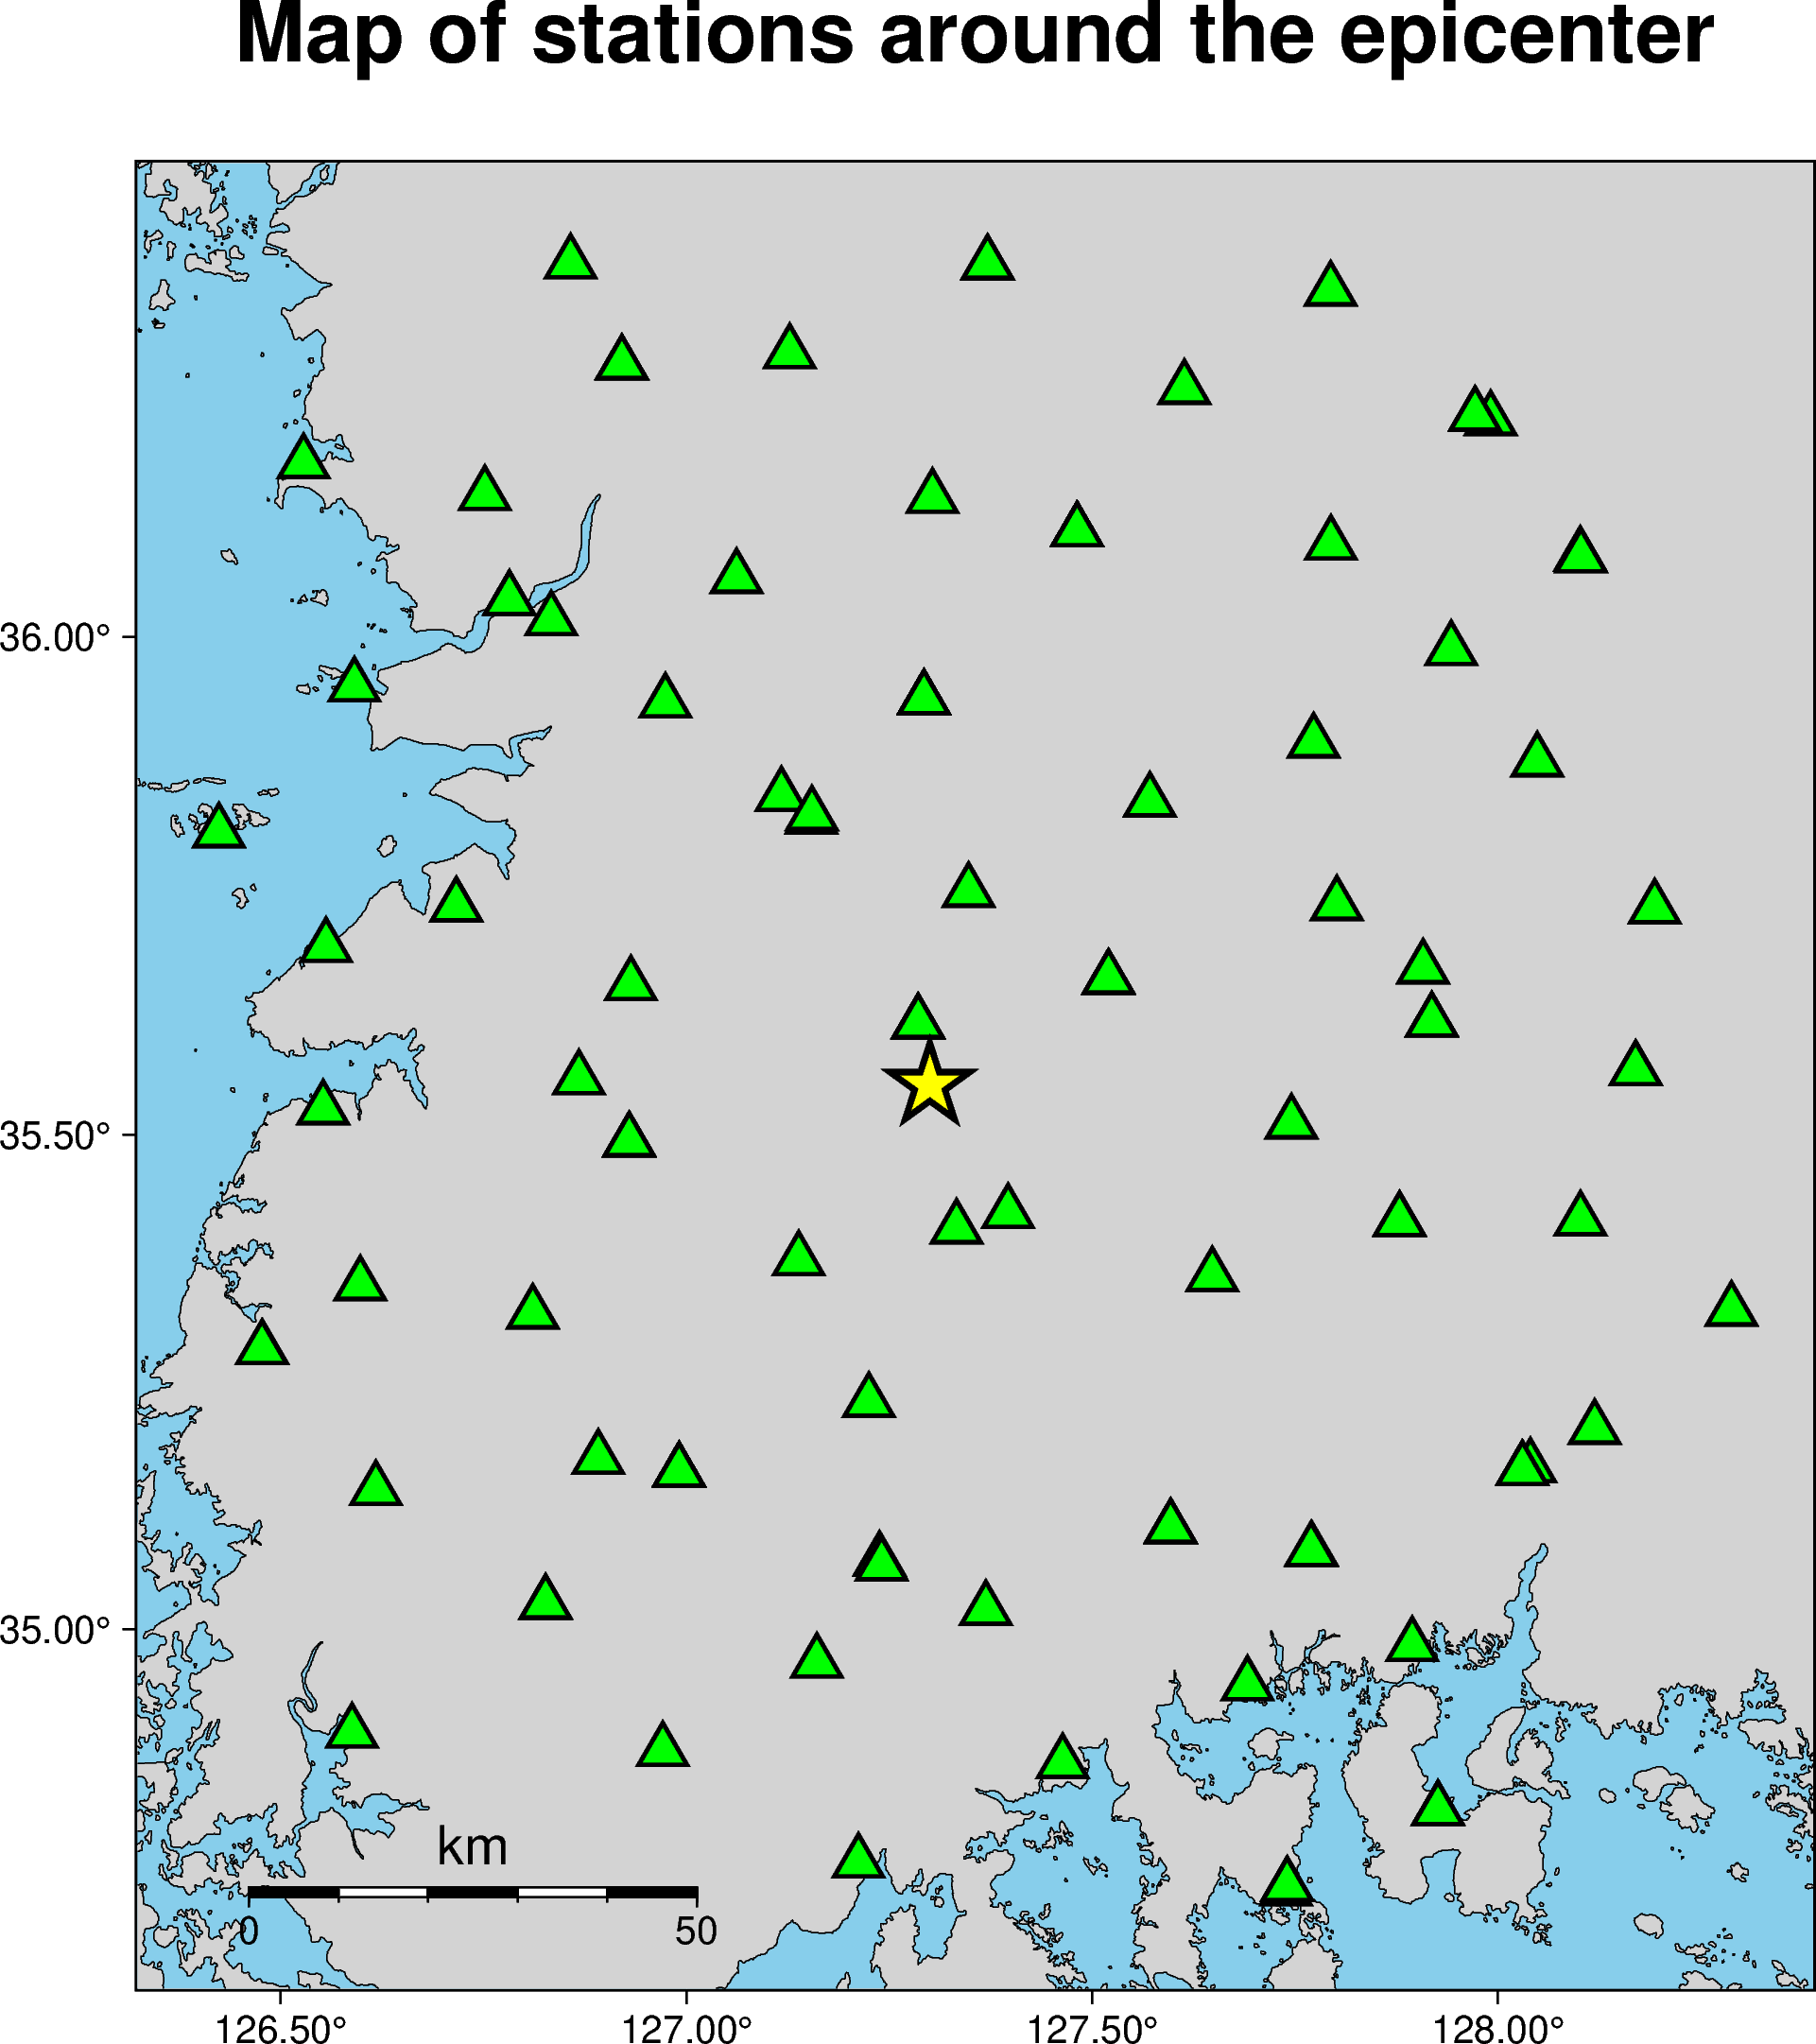

In [7]:
fig=pmt.Figure()
pmt.config(FORMAT_GEO_MAP="ddd.xx", MAP_FRAME_TYPE="plain")

region=[selected_table["Longitude"].min()-0.1, selected_table["Longitude"].max()+0.1, selected_table["Latitude"].min()-0.1, selected_table["Latitude"].max()+0.1]

fig.basemap(region=region, projection="M15c", frame=["a", '+t"Map of stations around the epicenter"'])
fig.coast(land="lightgray", water="skyblue" ,shorelines=True, map_scale=f"n0.2/0.05+f+l+c{evlo}/{evla}+w50.0")

# Plot stations
fig.plot(x=selected_table["Longitude"], y=selected_table["Latitude"], style="t0.5c", fill="green", pen="1p,black")

# Plot epicenter
fig.plot(x=evlo, y=evla, style="a0.75c", fill="yellow", pen="1.5p,black")

fig.show(width=600)